# Example 3.4: GA for Four-Bar Mechanism Trajectory Synthesis
**Chapter 3 · Four Bar Mechanisms with Genetic Algorithms**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Apply a real-coded GA to synthesize a four-bar mechanism that traces a target **elliptical trajectory**. The chromosome is `[a, b, c, xp, yp]` with `d = 1.0` fixed. Use `N_POP=60`, `N_GEN=120`, `Pm=0.12`, and a tournament size of 3.

**Goal:** Apply the GA to a real mechanism design problem, where fitness measures the mean squared error between trajectories.

In [3]:
# ── Imports─────────────────────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

In [4]:
import builtins
# ── Kinematics of the four-bar mechanism ─────────────────────────────
def cuatro_barras_trayectoria(a, b, c, d, xp, yp, n_pts=30):
    """Calculates the trajectory of the coupler point (px, py)."""
    theta2 = linspace(0, 2*pi, n_pts, endpoint=False)
    px, py = [], []
    for t2 in theta2:
        K1 = d/a;  K2 = d/c;  K3 = (a**2-b**2+c**2+d**2)/(2*a*c)
        K4 = d/b;  K5 = (c**2-d**2-a**2-b**2)/(2*a*b)
        A  = cos(t2)-K1-K2*cos(t2)+K3;  B = -2*sin(t2);  C = K1-(K2+1)*cos(t2)+K3
        disc = B**2 - 4*A*C
        if disc < 0: px.append(nan); py.append(nan); continue
        A3 = cos(t2)-K1+K4*cos(t2)+K5;  B3 = -2*sin(t2);  C3 = K1+(K4-1)*cos(t2)+K5
        disc3 = B3**2 - 4*A3*C3
        if disc3 < 0: px.append(nan); py.append(nan); continue
        t3 = 2*arctan2(-B3 - sqrt(disc3), 2*A3)
        Ax = a*cos(t2);  Ay = a*sin(t2)
        px.append(Ax + xp*cos(t3) - yp*sin(t3))
        py.append(Ay + xp*sin(t3) + yp*cos(t3))
    return array(px), array(py)

def trayectoria_objetivo(n_pts=30):
    """Target ellipse centered at (1.5, 0)."""
    t = linspace(0, 2*pi, n_pts, endpoint=False)
    return 1.5 + 0.8*cos(t), 1.0*sin(t)

def aptitud(crom, xd, yd):
    """Mean squared error between generated and target trajectory."""
    a, b, c, xp, yp = crom;  d = 1.0
    if a <= 0 or b <= 0 or c <= 0: return 1e6
    s = builtins.min(a, b, c, d);  l = builtins.max(a, b, c, d)
    if s + l > (a + b + c + d) - s - l + 0.001: return 1e6
    try:
        px, py = cuatro_barras_trayectoria(a, b, c, d, xp, yp, len(xd))
    except:
        return 1e6
    valid = ~(isnan(px) | isnan(py))
    if valid.sum() < 5: return 1e6
    return mean(sqrt((px[valid]-xd[valid])**2 + (py[valid]-yd[valid])**2))

# ── Genetic Algorithm ───────────────────────────────────────────────────
random.seed(42)
N_POP, N_GEN = 60, 120;  PM = 0.12
BLO = array([0.3, 0.5, 0.3, -0.5, -0.5])
BHI = array([1.5, 2.0, 1.5,  0.5,  0.5])
xd, yd = trayectoria_objetivo(30)
pop = random.uniform(0, 1, (N_POP, 5)) * (BHI - BLO) + BLO
hist = [];  mejor_ever = None;  mejor_apt = 1e9

for gen in range(N_GEN):
    fit = array([aptitud(p, xd, yd) for p in pop])
    ib = argmin(fit)
    if fit[ib] < mejor_apt:
        mejor_apt = fit[ib];  mejor_ever = pop[ib].copy()
    hist.append(mejor_apt)
    padres = array([pop[c[argmin(fit[c])]]
                    for c in [random.choice(N_POP, 3, replace=False)
                              for _ in range(N_POP)]])
    hijos = []
    for i in range(0, N_POP - 1, 2):
        av = random.uniform(0, 1)
        hijos.append(av*padres[i] + (1-av)*padres[i+1])
        hijos.append((1-av)*padres[i] + av*padres[i+1])
    pop = array(hijos[:N_POP])
    for i in range(N_POP):
        if random.rand() < PM:
            k = random.randint(5)
            pop[i, k] += random.normal(0, 0.05*(BHI[k]-BLO[k]))
    pop = clip(pop, BLO, BHI);  pop[0] = mejor_ever

print(f"GA Trajectory Error: E = {mejor_apt:.4f}")
print(f"Optimal chromosome: a={mejor_ever[0]:.3f}, b={mejor_ever[1]:.3f}, c={mejor_ever[2]:.3f}")
print(f"  xp={mejor_ever[3]:.3f}, yp={mejor_ever[4]:.3f}")
print(f"  (fixed d = 1.000)")
print(f"Convergence gen 1→{N_GEN}: {hist[0]:.4f} → {hist[-1]:.4f}")



GA Trajectory Error: E = 0.9892
Optimal chromosome: a=1.415, b=0.808, c=0.389
  xp=-0.177, yp=0.068
  (fixed d = 1.000)
Convergence gen 1→120: 1.1729 → 0.9892


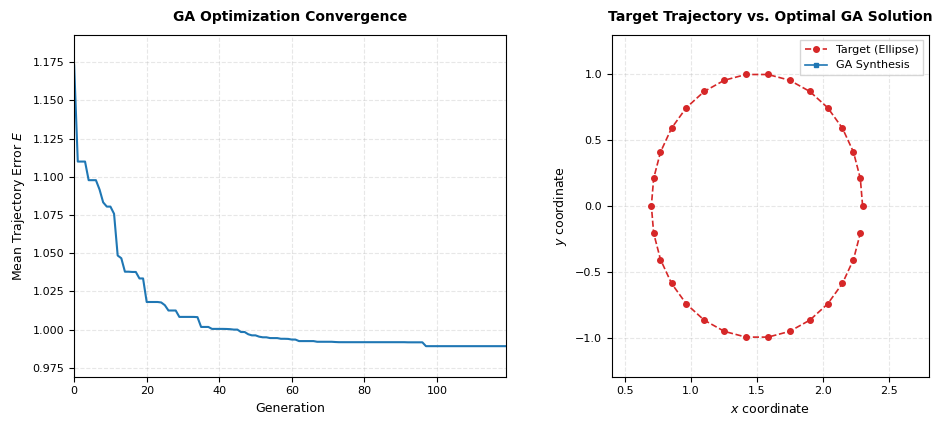

In [6]:
import os
import glob
import matplotlib.pyplot as plt
from numpy import isnan

# ── Automated Filename System (Springer Guidelines) ─────────────────
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex3_4_ga_trajectory_synthesis"
except Exception:
    notebook_name = "ex3_4_ga_trajectory_synthesis"

# ── Compute Trajectory with Optimal Parameters ──────────────────────
px_opt, py_opt = cuatro_barras_trayectoria(*mejor_ever, 1.0, 60)
mask = ~(isnan(px_opt) | isnan(py_opt))

# ── Global Plot Settings (Springer Sans-Serif Format) ───────────────
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 8,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# Create a controlled-size double subplot suitable for academic books
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.3))

# ── Left Plot: GA Convergence ──────────────────────────────────────
ax1.plot(hist, color='#1f77b4', lw=1.5, label='Best Fitness')
ax1.set_xlabel('Generation', fontsize=9)
ax1.set_ylabel('Mean Trajectory Error $E$', fontsize=9)
ax1.set_title('GA Optimization Convergence', fontsize=10, fontweight='bold', pad=10)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.set_xlim(0, len(hist) - 1)
# Proactive margin to avoid label clipping and leave blank space
ax1.set_ylim(min(hist) - 0.02, max(hist) + 0.02)

# ── Right Plot: Trajectory Synthesis ────────────────────────────────
ax2.plot(xd, yd, 'o--', color='#d62728', ms=4, lw=1.2, label='Target (Ellipse)')
ax2.plot(px_opt[mask], py_opt[mask], 's-', color='#1f77b4', ms=3.5, lw=1.2, label='GA Synthesis')
ax2.set_aspect('equal')
ax2.set_xlabel('$x$ coordinate', fontsize=9)
ax2.set_ylabel('$y$ coordinate', fontsize=9)
ax2.set_title('Target Trajectory vs. Optimal GA Solution', fontsize=10, fontweight='bold', pad=10)
ax2.grid(True, linestyle='--', alpha=0.3)

# Proactive limits to ensure legends and data points never overlap
ax2.set_xlim(min(xd) - 0.3, max(xd) + 0.5)
ax2.set_ylim(min(yd) - 0.3, max(yd) + 0.3)
ax2.legend(loc='best', fontsize=8, frameon=True, fancybox=False, edgecolor='#cccccc')

# Adjust layout beautifully
plt.tight_layout()

# ── Mandatory Double Export ──────────────────────────────────────────
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()